# PartB - Suppl. Fig. SXX: are steady-state and response-timescale glacier model differences related?

Tendency analysis for the discussion: does a glacier model that deviates from the other glacier models in its steady-state mass also deviate in its response timescale?

For every RGI region and climate scenario, both quantities are expressed as the difference of each glacier model to the multi-model median of that region and scenario (this removes the common dependence on the global warming level):
- steady state: difference in % of the 2020 mass (steady state shifted to 2020, as in PartB_3)
- response timescale: relative difference to the multi-model median (non-shifted volume response timescale, as in PartB_0 / PartB_2; OGGM-VAS removed). The statistics use the log-ratio (a twice as long and a half as long response timescale are then equally far from the multi-model median); the ranks, and hence the Spearman correlations, are the same for the log-ratio and the relative difference in %.

Per region and glacier model, we take the median over the climate scenarios of the temperature bin (= the systematic behaviour of the glacier model). Global is not used, as it is the sum of the same four global models.

Figures:
1. `scatter`: one dot per region and glacier model (**supplement**)
2. `rank_corr`: Spearman rank correlation per region and its mean over the regions (analysis only)
3. `per_model`: systematic behaviour of every glacier model over the regions (analysis only)

We also looked at the other temperature bins and at the 50 % response timescale (see the check at the end).

In [2]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, rankdata

In [3]:
plt.rcParams["pdf.use14corefonts"] = False  # don't convert text to path
plt.rcParams['pdf.fonttype'] = 42  # keep the text editable in the pdf

## Settings

In [4]:
# data, created in PartB_3 (steady state) and PartB_0 (non-shifted response timescale)
fn_steady_state = 'PartB_data/steady_state_relative_volume_change.csv'
fn_resp_time = 'PartB_data/resp_time_non_shifted_for_deltaT_rgi_reg_roll_volume_area_21yravg.csv'

temp_bin = [2.0, 4.0]            # global warming bin in °C
# temp_bin = [4.0, 7.0]            # global warming bin in °C
# temp_bin = [-0.15, 2.0]          # global warming bin in °C (lowest experiment is at -0.14°C)

resp_time_change = -80           # response timescale to reach 80 % of the total change (or -50)
min_models = 4                   # region-scenario combinations with fewer glacier models (with both values) are not used
alpha = 0.05                     # significance level; correlations with p >= alpha are shown in grey
n_perm = 20000                   # number of permutations for the p-value of the mean over the regions
seed = 0

# y-axis of the scatter plot: 'linear' (relative difference in %) or 'log' (log-ratio, symmetric for
# a factor 2 longer / shorter). The statistics always use the log-ratio.
y_scale = 'linear'

fig_size_scatter_cm = (9, 8.5)          # one-column figure of the journal
fig_size_per_model_cm = (18, 12.5)      # two-column figure of the journal

# per-model figure: region numbers are only written next to points outside this box
# (steady-state difference in % of 2020 mass, response timescale difference in %)
label_box = (10, 50)
# per-model figure: manual position of single region numbers ('above', 'below', 'left', 'right'),
# all others are placed automatically
label_pos_manual = {('GLIMB', '10'): 'above', ('GLIMB', '12'): 'above', ('GloGEMflow', '3'): 'left',
                    ('PyGEM-OGGM', '13'): 'left', ('PyGEM-OGGM', '1'): 'below'}
# per-model figure: the direction in the subtitle is written in bold if it is a clear tendency
#  'n_regions': at least bold_min_regions of the 19 regions in the same direction
#  'sign_test': two-sided sign test over the regions (without the regions where the glacier model is the "median estimate"), p < alpha
bold_rule = 'n_regions'
bold_min_regions = 14
fig_dir = 'figures_partB/ss_vs_resp_time_dependence/'
os.makedirs(fig_dir, exist_ok=True)

## Names and colours of the glacier models and regions

In [5]:
reg_names = {'01': 'Alaska', '02': 'W Canada & US', '03': 'Arctic Canada N', '04': 'Arctic Canada S',
             '05': 'Greenland Periphery', '06': 'Iceland', '07': 'Svalbard & Jan Mayen', '08': 'Scandinavia',
             '09': 'Russian Arctic', '10': 'North Asia', '11': 'Central Europe', '12': 'Caucasus & Middle East',
             '13': 'Central Asia', '14': 'South Asia W', '15': 'South Asia E', '16': 'Low Latitudes',
             '17': 'Southern Andes', '18': 'New Zealand', '19': 'Subantarctic & Antarctic Islands'}
regs = list(reg_names)

global_models = ['PyGEM-OGGM', 'GloGEMflow', 'OGGM', 'GLIMB']
regional_models = ['GloGEMflow3D', 'Kraaijenbrink', 'GO', 'CISM2']
model_names_csv = {'PyGEM-OGGM_v13': 'PyGEM-OGGM', 'OGGM_v16': 'OGGM'}   # names in the csv file, all others are the same
dict_model_col = {'PyGEM-OGGM': '#5fb0e1', 'GloGEMflow': '#d18c14', 'OGGM': '#ca79bc', 'GLIMB': '#fab1e5',
                  'GloGEMflow3D': '#0f9373', 'Kraaijenbrink': '#c46011', 'GO': '#e5d73d', 'CISM2': '#562e10'}

## 1. Prepare the data

In [6]:
pd_ss = pd.read_csv(fn_steady_state, index_col=0)
pd_ss['model'] = pd_ss.model_author.replace(model_names_csv)
pd_ss['exp'] = pd_ss.gcm + '_' + pd_ss.period_scenario
pd_ss = pd_ss.rename(columns={'relative volume change (in %)': 'ss'})

pd_rt = pd.read_csv(fn_resp_time, index_col=0)
pd_rt = pd_rt.loc[(pd_rt.metric == 'volume_m3') & (pd_rt.model_author != 'OGGM-VAS')].copy()
pd_rt['model'] = pd_rt.model_author.replace(model_names_csv)
pd_rt['rgi_reg'] = pd_rt.rgi_reg.str.replace('RGI', '').replace({'All': 'Global'})
pd_rt = pd_rt.rename(columns={'gcm_period_scenario': 'exp'})
pd_rt['tau'] = pd_rt[f'resp_time_{resp_time_change}%']

pd_both = pd_ss[['rgi_reg', 'model', 'exp', 'temp_ch_ipcc', 'ss']].merge(
    pd_rt[['rgi_reg', 'model', 'exp', 'temp_ch_ipcc', 'tau']], on=['rgi_reg', 'model', 'exp'], suffixes=('', '_rt'))
assert np.allclose(pd_both.temp_ch_ipcc, pd_both.temp_ch_ipcc_rt)
pd_both = pd_both.loc[pd_both.rgi_reg.isin(regs)]

# difference of every glacier model to the median model of the region and climate scenario
grp = ['rgi_reg', 'exp']
pd_both = pd_both.loc[pd_both.groupby(grp).model.transform('count') >= min_models].copy()
pd_both['d_ss'] = pd_both.ss - pd_both.groupby(grp).ss.transform('median')
pd_both['d_tau'] = np.log(pd_both.tau / pd_both.groupby(grp).tau.transform('median'))

# systematic behaviour: median over the climate scenarios of the temperature bin
pd_bin = pd_both.loc[(pd_both.temp_ch_ipcc >= temp_bin[0]) & (pd_both.temp_ch_ipcc <= temp_bin[1])]
pd_sys = pd_bin.groupby(['rgi_reg', 'model']).agg(d_ss=('d_ss', 'median'), d_tau=('d_tau', 'median'),
                                                   n_exp=('d_ss', 'size')).reset_index()
pd_sys['d_tau_pct'] = 100 * (np.exp(pd_sys.d_tau) - 1)    # relative difference to the multi-model median in %

# robustness over the climate scenarios: share of scenarios with the same sign as the median
def _share_same_sign(x):
    return np.mean(np.sign(x) == np.sign(x.median())) if x.median() != 0 else 0
_rob = pd_bin.groupby(['rgi_reg', 'model']).agg(ss_share=('d_ss', _share_same_sign),
                                                tau_share=('d_tau', _share_same_sign)).reset_index()
pd_sys = pd_sys.merge(_rob, on=['rgi_reg', 'model'])
pd_sys['ss_robust'] = pd_sys.ss_share >= 0.83
pd_sys['tau_robust'] = pd_sys.tau_share >= 0.83

# area response timescale (same file, metric area_m2): difference to the median model, same steps as for the volume
pd_rt_a = pd.read_csv(fn_resp_time, index_col=0)
pd_rt_a = pd_rt_a.loc[(pd_rt_a.metric == 'area_m2') & (pd_rt_a.model_author != 'OGGM-VAS')].copy()
pd_rt_a['model'] = pd_rt_a.model_author.replace(model_names_csv)
pd_rt_a['rgi_reg'] = pd_rt_a.rgi_reg.str.replace('RGI', '').replace({'All': 'Global'})
pd_rt_a = pd_rt_a.rename(columns={'gcm_period_scenario': 'exp', f'resp_time_{resp_time_change}%': 'tau_area'})
_a = pd_bin[['rgi_reg', 'model', 'exp']].merge(pd_rt_a[['rgi_reg', 'model', 'exp', 'tau_area']],
                                               on=['rgi_reg', 'model', 'exp'], how='left')
_a['d_tau_area'] = np.log(_a.tau_area / _a.groupby(grp).tau_area.transform('median'))
pd_sys = pd_sys.merge(_a.groupby(['rgi_reg', 'model']).d_tau_area.median().reset_index(), on=['rgi_reg', 'model'])
pd_sys['area_same_direction'] = np.sign(pd_sys.d_tau_area) == np.sign(pd_sys.d_tau)
# Global (sum of all regions, only the four global glacier models): same steps, shown as a square in the per-model figure
_g = pd_ss.loc[pd_ss.rgi_reg == 'Global', ['model', 'exp', 'temp_ch_ipcc', 'ss']].merge(
    pd_rt.loc[pd_rt.rgi_reg == 'Global', ['model', 'exp', 'tau']], on=['model', 'exp'])
_g = _g.loc[(_g.temp_ch_ipcc >= temp_bin[0]) & (_g.temp_ch_ipcc <= temp_bin[1])]
_g = _g.loc[_g.groupby('exp').model.transform('count') == len(global_models)].copy()
_g['d_ss'] = _g.ss - _g.groupby('exp').ss.transform('median')
_g['d_tau'] = np.log(_g.tau / _g.groupby('exp').tau.transform('median'))
pd_glob = _g.groupby('model')[['d_ss', 'd_tau']].median()
pd_glob['d_tau_pct'] = 100 * (np.exp(pd_glob.d_tau) - 1)
print('Global: climate scenarios with all four global glacier models:', _g.exp.nunique())
print(pd_glob.round(1))
print('climate scenarios in the bin:', pd_bin.exp.nunique())
print(f'share with the same sign in >= 83 % of the scenarios: steady state {pd_sys.ss_robust.mean():.2f}, '
      f'response timescale {pd_sys.tau_robust.mean():.2f}')
print(f'area response timescale differs in the same direction as the volume response timescale: '
      f'{pd_sys.area_same_direction.mean():.2f}; rank correlation volume vs area: '
      f'{spearmanr(pd_sys.d_tau, pd_sys.d_tau_area, nan_policy="omit")[0]:.2f}')
pd_sys.pivot(index='rgi_reg', columns='model', values='n_exp')

Global: climate scenarios with all four global glacier models: 31
            d_ss  d_tau  d_tau_pct
model                             
GLIMB        3.6    0.7      102.8
GloGEMflow  18.3   -0.4      -36.0
OGGM        -3.6   -0.5      -39.8
PyGEM-OGGM -12.2    0.3       34.5
climate scenarios in the bin: 31
share with the same sign in >= 83 % of the scenarios: steady state 0.71, response timescale 0.77
area response timescale differs in the same direction as the volume response timescale: 0.83; rank correlation volume vs area: 0.84


model,CISM2,GLIMB,GO,GloGEMflow,GloGEMflow3D,Kraaijenbrink,OGGM,PyGEM-OGGM
rgi_reg,,,,,,,,
01,NaN,31.0,NaN,31.0,NaN,NaN,31.0,31.0
02,NaN,31.0,NaN,31.0,31.0,NaN,31.0,31.0
03,NaN,21.0,NaN,21.0,NaN,NaN,21.0,21.0
04,NaN,31.0,NaN,31.0,NaN,NaN,31.0,31.0
05,NaN,31.0,NaN,31.0,NaN,NaN,31.0,31.0
06,NaN,31.0,31.0,31.0,31.0,NaN,31.0,31.0
07,NaN,31.0,NaN,31.0,NaN,NaN,31.0,31.0
08,NaN,31.0,NaN,31.0,31.0,NaN,31.0,31.0
09,NaN,31.0,NaN,31.0,NaN,NaN,31.0,31.0


## 2. Rank correlation per region and permutation tests

Two different tests:
- **per region:** exact permutation test of the Spearman rank correlation over the 4 to 6 glacier models (all $n!$ orderings of the glacier models). The usual p-value of `scipy.stats.spearmanr` uses an approximation that is not valid for so few values.
- **mean over the regions:** the mean of the 19 correlations is the test statistic (this is **not** a mean of p-values). Its p-value comes from shuffling the glacier model labels within each region at the same time. This test can only become significant if the correlations point in the same direction in many regions.

In [7]:
import itertools

def _corr(a, b):
    a, b = a - a.mean(), b - b.mean()
    denom = np.sqrt((a * a).sum() * (b * b).sum())
    return (a * b).sum() / denom if denom > 0 else np.nan

def spearman_exact(x, y):
    """Spearman rank correlation and its exact two-sided permutation p-value (all n! orderings)"""
    rx, ry = rankdata(x), rankdata(y)
    obs = _corr(rx, ry)
    null = np.array([_corr(rx, np.array(perm)) for perm in itertools.permutations(ry)])
    return obs, np.mean(np.abs(null) >= abs(obs) - 1e-12)

def rho_per_region(pd_s):
    out = {}
    for r in regs:
        _s = pd_s.loc[pd_s.rgi_reg == r]
        out[r] = (*spearman_exact(_s.d_ss.values, _s.d_tau.values), len(_s))
    return pd.DataFrame(out, index=['rho', 'p', 'n_models']).T

def perm_test_mean_rho(pd_s, n_perm=n_perm, seed=seed):
    """mean of the within-region Spearman correlations, and its two-sided p-value when the
    glacier model labels are shuffled within each region (= no relation)"""
    rng = np.random.default_rng(seed)
    r_ss = [rankdata(pd_s.loc[pd_s.rgi_reg == r, 'd_ss']) for r in regs]
    r_tau = [rankdata(pd_s.loc[pd_s.rgi_reg == r, 'd_tau']) for r in regs]
    obs = np.nanmean([_corr(a, b) for a, b in zip(r_ss, r_tau)])
    null = np.array([np.nanmean([_corr(a, rng.permutation(b)) for a, b in zip(r_ss, r_tau)]) for _ in range(n_perm)])
    p = (np.sum(np.abs(null) >= abs(obs) - 1e-12) + 1) / (n_perm + 1)
    return obs, p, null

# smallest p-value that the exact test can give with n glacier models
for n in [3, 4, 5, 6]:
    print(f'{n} glacier models: smallest possible p = {spearman_exact(np.arange(n), np.arange(n))[1]:.3f}')

3 glacier models: smallest possible p = 0.333
4 glacier models: smallest possible p = 0.083
5 glacier models: smallest possible p = 0.017
6 glacier models: smallest possible p = 0.003


In [8]:
res_all = rho_per_region(pd_sys)
mean_all, p_all, null_all = perm_test_mean_rho(pd_sys)
print(f'regions with p < {alpha}: {res_all.index[res_all.p < alpha].tolist()}')
print(f'mean over the regions: rho = {mean_all:.2f} (positive in {(res_all.rho > 0).sum()} of {res_all.rho.notna().sum()} regions), '
      f'p = {p_all:.2f}, 95 % range if no relation: {np.quantile(null_all, [0.025, 0.975]).round(2)}')
res_all.round(3)

regions with p < 0.05: []
mean over the regions: rho = 0.16 (positive in 13 of 19 regions), p = 0.19, 95 % range if no relation: [-0.23  0.23]


,rho,p,n_models
01,0.200,0.917,4.0
02,0.359,0.633,5.0
03,-0.600,0.417,4.0
04,-0.400,0.750,4.0
05,0.600,0.417,4.0
06,0.029,1.000,6.0
07,0.800,0.333,4.0
08,-0.154,0.833,5.0
09,-0.800,0.333,4.0
10,0.000,1.000,5.0


**Check:** does one glacier model drive the mean correlation? (leave one glacier model out)

In [9]:
mean_loo = {}
for m in pd_sys.model.unique():
    mean_loo[m] = np.nanmean(rho_per_region(pd_sys.loc[pd_sys.model != m]).rho)
    print(f'without {m:13s}: mean rho = {mean_loo[m]:.2f}')

model_out = max(mean_loo, key=lambda m: abs(mean_loo[m] - mean_all))
pd_sys_out = pd_sys.loc[pd_sys.model != model_out]
mean_out, p_out, null_out = perm_test_mean_rho(pd_sys_out)
print(f'without {model_out}: mean rho = {mean_out:.2f}, p = {p_out:.2f}')
print(f'{model_out}: median difference of the response timescale to the median model = '
      f'{100 * (np.exp(pd_sys.loc[pd_sys.model == model_out, "d_tau"].median()) - 1):.0f} %, '
      f'longer than the median model in {(pd_sys.loc[pd_sys.model == model_out, "d_tau"] > 0).sum()} of 19 regions')

without GLIMB        : mean rho = -0.11
without GloGEMflow   : mean rho = 0.24
without OGGM         : mean rho = 0.16
without PyGEM-OGGM   : mean rho = 0.22
without GloGEMflow3D : mean rho = 0.15
without GO           : mean rho = 0.20
without CISM2        : mean rho = 0.18
without Kraaijenbrink: mean rho = 0.18
without GLIMB: mean rho = -0.11, p = 0.45
GLIMB: median difference of the response timescale to the median model = 79 %, longer than the median model in 19 of 19 regions


**Attention:**
- In the regions with only four glacier models, the per-region test can never give p < 0.05 (smallest possible p = 0.083), so a grey dot there means *not testable*, not *no relation*. Without one glacier model, these regions have only three glacier models left (smallest possible p = 0.33), so the figure shows the result without this glacier model only for the mean over the regions.
- 19 tests per region at the 5 % level: about one region is expected to be significant by chance (no correction for multiple testing is applied; here it does not matter, as no region is significant).

The permutation test treats the regions as independent, but the same glacier models are used in every region. The 95 % range if there is no relation is therefore too narrow, i.e. the p-values are rather too small than too large.

## 3. Supplement figure: steady-state vs. response-timescale difference

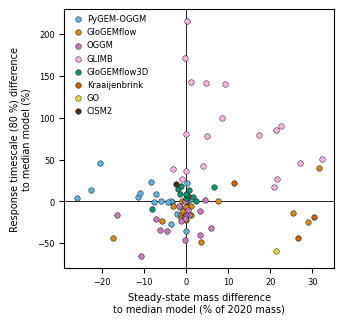

In [10]:
fs = 7
fig, ax = plt.subplots(figsize=(fig_size_scatter_cm[0] / 2.54, fig_size_scatter_cm[1] / 2.54))
y_col = 'd_tau_pct' if y_scale == 'linear' else 'd_tau'
for m in global_models + regional_models:
    _p = pd_sys.loc[pd_sys.model == m]
    if len(_p) > 0:
        ax.scatter(_p.d_ss, _p[y_col], s=16, color=dict_model_col[m], edgecolor='k', lw=0.3, label=m, zorder=3)
ax.axhline(0, color='k', lw=0.6)
ax.axvline(0, color='k', lw=0.6)
if y_scale == 'log':
    y_ticks = np.array([-75, -50, 0, 100, 200, 400])
    ax.set_yticks(np.log(1 + y_ticks / 100))
    ax.set_yticklabels([f'{v:+d}' if v != 0 else '0' for v in y_ticks])
ax.set_xlabel('Steady-state mass difference\nto multi-model median (% of 2020 mass)', fontsize=fs)
ax.set_ylabel(f'Response timescale ({abs(resp_time_change)} %) difference\nto median model (%)', fontsize=fs)
ax.tick_params(labelsize=fs - 1)
ax.legend(fontsize=fs - 1, loc='upper left', frameon=False, handletextpad=0.1, borderaxespad=0.2)
plt.tight_layout()
fn_out = (f'{fig_dir}/suppl_steady_state_vs_resp_time_{abs(resp_time_change)}_model_differences_scatter_{y_scale}_'
          f'temp_bin_{temp_bin[0]}_{temp_bin[1]}')
plt.savefig(fn_out + '.png', dpi=300)
plt.savefig(fn_out + '.pdf')

## 4. Analysis figure: rank correlation per region (not for the manuscript)

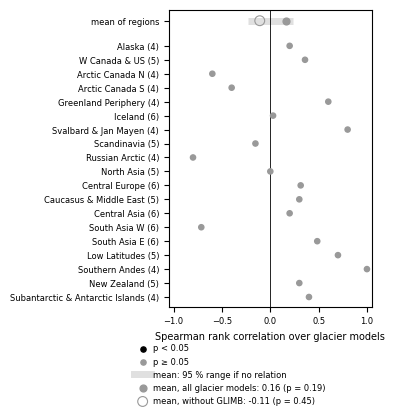

In [11]:
fig, ax_b = plt.subplots(figsize=(10 / 2.54, 11 / 2.54))
col_sig = lambda p: 'k' if p < alpha else '0.6'
y = np.arange(len(regs))[::-1]
y_mean = len(regs) + 0.8
lo, hi = np.quantile(null_all, [0.025, 0.975])
ax_b.plot([lo, hi], [y_mean, y_mean], color='0.88', lw=5, solid_capstyle='butt', zorder=1)
ax_b.scatter(res_all.loc[regs, 'rho'], y, c=[col_sig(p) for p in res_all.loc[regs, 'p']], s=14, zorder=3)
ax_b.scatter(mean_all, y_mean, color=col_sig(p_all), s=24, zorder=4)
ax_b.scatter(mean_out, y_mean, facecolor='none', edgecolor=col_sig(p_out), lw=0.8, s=50, zorder=4)
ax_b.axvline(0, color='k', lw=0.6)
ax_b.set_yticks(list(y) + [y_mean])
ax_b.set_yticklabels([f'{reg_names[r]} ({int(res_all.loc[r, "n_models"])})' for r in regs] + ['mean of regions'], fontsize=fs - 1)
ax_b.set_ylim(-0.7, y_mean + 0.8)
ax_b.set_xlim(-1.05, 1.05)
ax_b.set_xlabel('Spearman rank correlation over glacier models', fontsize=fs)
ax_b.tick_params(labelsize=fs - 1)
h = [ax_b.scatter([], [], color='k', s=14), ax_b.scatter([], [], color='0.6', s=14),
     ax_b.plot([], [], color='0.88', lw=5)[0],
     ax_b.scatter([], [], color='0.6', s=24), ax_b.scatter([], [], facecolor='none', edgecolor='0.6', lw=0.8, s=50)]
lab_b = [f'p < {alpha}', f'p ≥ {alpha}', 'mean: 95 % range if no relation',
         f'mean, all glacier models: {mean_all:.2f} (p = {p_all:.2f})',
         f'mean, without {model_out}: {mean_out:.2f} (p = {p_out:.2f})']
ax_b.legend(h, lab_b, fontsize=fs - 1, loc='upper center', bbox_to_anchor=(0.3, -0.1), frameon=False, handletextpad=0.2)
plt.tight_layout()
fn_out = (f'{fig_dir}/analysis_steady_state_vs_resp_time_{abs(resp_time_change)}_rank_corr_per_region_'
          f'temp_bin_{temp_bin[0]}_{temp_bin[1]}')
plt.savefig(fn_out + '.png', dpi=300)

## 5. Analysis: systematic behaviour of every glacier model over the regions (not for the manuscript)

For every glacier model: in how many regions is it above the median model, separately for the steady-state mass and for the response timescale? The two-sided sign test (binomial test, 50 % chance to be above the median model) gives a p-value for a consistent direction over the regions.

**Attention:**
- Regions are not fully independent (e.g. similar climate or glacier characteristics), so the p-values are only indicative.
- With 4 glacier models, the median model is the mean of the two middle glacier models, so in every region exactly two glacier models are above it (if there are no ties). A glacier model that is always above the median model in one quantity therefore forces the others to be more often below it.
- CISM2, GO and Kraaijenbrink are available in only 1 to 3 regions, so they cannot be tested.

In [12]:
from scipy.stats import binomtest

def sign_summary(x):
    n_pos, n = int((x > 0).sum()), int((x != 0).sum())
    return n_pos, n, binomtest(n_pos, n, 0.5).pvalue if n > 0 else np.nan

rows = []
for m in global_models + regional_models:
    _p = pd_sys.loc[pd_sys.model == m]
    if len(_p) == 0:
        continue
    ss_pos, ss_n, ss_p = sign_summary(_p.d_ss)
    tau_pos, tau_n, tau_p = sign_summary(_p.d_tau)
    rows.append({'model': m, 'n_regions': len(_p),
                 'median d_ss (% of 2020 mass)': _p.d_ss.median(),
                 'regions with more ss mass': f'{ss_pos}/{ss_n}', 'p (ss)': ss_p,
                 'median d_tau (%)': _p.d_tau_pct.median(),
                 'regions with longer tau': f'{tau_pos}/{tau_n}', 'p (tau)': tau_p})
pd_per_model = pd.DataFrame(rows).set_index('model')
pd_per_model.round(3)

,n_regions,median d_ss (% of 2020 mass),regions with more ss mass,p (ss),median d_tau (%),regions with longer tau,p (tau)
model,,,,,,,
PyGEM-OGGM,19,-4.392,2/17,0.002,0.000,8/16,1.000
GloGEMflow,19,0.060,10/17,0.629,-11.278,3/17,0.013
OGGM,19,-0.180,6/17,0.332,-18.932,2/18,0.001
GLIMB,19,5.073,14/19,0.064,79.167,19/19,0.000
GloGEMflow3D,11,0.009,6/10,0.754,8.333,9/10,0.021
Kraaijenbrink,3,26.674,3/3,0.250,-18.710,1/3,1.000
GO,1,21.377,1/1,1.000,-59.736,0/1,1.000
CISM2,1,-2.376,0/1,1.000,20.755,1/1,1.000


## 6. Main-figure candidate: systematic behaviour of every glacier model

Four panels for the global glacier models, one panel for the regional glacier models, one panel for the legend. Region numbers are only written for points outside `label_box`.

Subtitles (global glacier models only): number of regions in which the glacier model has less / more steady-state mass, and a shorter / longer response timescale, than the median model. The two numbers do not always add up to 19: in some regions with five glacier models, the glacier model is itself the median model (difference = 0), these regions are not counted. Whether a direction is consistent over the regions (sign test) is given in the table of section 5.

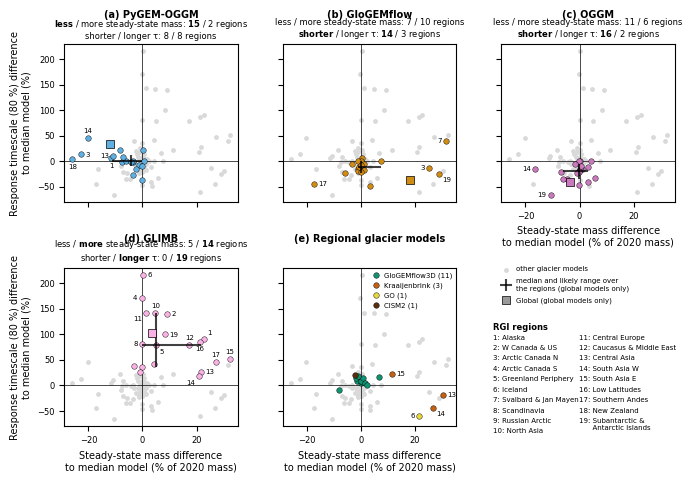

In [12]:
import textwrap
panels = [[m] for m in global_models] + [regional_models]
fig, axs = plt.subplots(2, 3, figsize=(fig_size_per_model_cm[0] / 2.54, fig_size_per_model_cm[1] / 2.54),
                        sharex=True, sharey=True)
y_col = 'd_tau_pct' if y_scale == 'linear' else 'd_tau'
y_box = label_box[1] if y_scale == 'linear' else np.log(1 + label_box[1] / 100)
y_box_lo = -label_box[1] if y_scale == 'linear' else np.log(1 - label_box[1] / 100)

from matplotlib.legend_handler import HandlerBase
cross_style = dict(color='k', lw=1.5, alpha=0.75, solid_capstyle='butt', zorder=4)

class HandlerCross(HandlerBase):
    """legend symbol: a cross like the median / 17-83 % range cross in the panels"""
    def create_artists(self, legend, orig_handle, x0, y0, width, height, fontsize, trans):
        xc, yc, d = x0 + width / 2, y0 + height / 2, 0.75 * height
        return [plt.Line2D([xc - 1.6 * d, xc + 1.6 * d], [yc, yc], transform=trans, **cross_style),
                plt.Line2D([xc, xc], [yc - 1.6 * d, yc + 1.6 * d], transform=trans, **cross_style)]

def _is_clear(x):
    """is the direction of the differences over the regions a clear tendency? returns -1, +1 or 0"""
    n_neg, n_pos = (x < 0).sum(), (x > 0).sum()
    if bold_rule == 'n_regions':
        clear = max(n_neg, n_pos) >= bold_min_regions
    else:
        clear = binomtest(int(max(n_neg, n_pos)), int(n_neg + n_pos), 0.5).pvalue < alpha
    return 0 if not clear else (1 if n_pos > n_neg else -1)

def _bf(t, bold):
    # bold text with mathtext (spaces need to be escaped)
    return r'$\bf{' + t.replace(' ', r'\ ') + '}$' if bold else t

def subtitle(_p, m):
    c_ss, c_tau = _is_clear(_p.d_ss), _is_clear(_p.d_tau)
    l1 = (f"{_bf('less', c_ss == -1)} / {_bf('more', c_ss == 1)} steady-state mass: "
          f"{_bf(str((_p.d_ss < 0).sum()), c_ss == -1)} / {_bf(str((_p.d_ss > 0).sum()), c_ss == 1)} regions")
    l2 = (f"{_bf('shorter', c_tau == -1)} / {_bf('longer', c_tau == 1)} τ: "
          f"{_bf(str((_p.d_tau < 0).sum()), c_tau == -1)} / {_bf(str((_p.d_tau > 0).sum()), c_tau == 1)} regions")
    return l1 + '\n' + l2

to_label = []   # (axis, x, y, text, model): placed after tight_layout, see place_labels
ax_points = {}  # coloured points per panel (for the label placement)

def place_labels(to_label, fs):
    """write the region numbers next to the points; for every label, the position (right, left, above, below, ...)
    is chosen that is furthest away from the coloured points of the panel and the labels already placed
    (staying inside the panel; positions to the right are slightly preferred)"""
    cands = [((3, 0), 'left', 'center'), ((-3, 0), 'right', 'center'), ((0, 3), 'center', 'bottom'),
             ((0, -3), 'center', 'top'), ((2.5, 2.5), 'left', 'bottom'), ((2.5, -2.5), 'left', 'top'),
             ((-2.5, 2.5), 'right', 'bottom'), ((-2.5, -2.5), 'right', 'top')]
    pt2px = fig.dpi / 72
    w_char, h_char = 0.6 * (fs - 2) * pt2px, 0.7 * (fs - 2) * pt2px    # approximate size of one digit in pixels
    manual = {'right': cands[0], 'left': cands[1], 'above': cands[2], 'below': cands[3]}
    for ax in dict.fromkeys(a[0] for a in to_label):
        # manually placed labels first, so that the automatic ones avoid them
        _lab = sorted([a for a in to_label if a[0] is ax], key=lambda a: (a[4], a[3]) not in label_pos_manual)
        pts = ax.transData.transform(np.array([(a[1], a[2]) for a in ax_points[ax]]))
        bbox = ax.get_window_extent()
        placed = []
        for _, x, y, t, m in _lab:
            p0 = ax.transData.transform((x, y))
            others = np.vstack([pts[np.hypot(*(pts - p0).T) > 0.5]] + placed) if len(pts) > 1 or placed else np.empty((0, 2))
            best, best_score = None, -np.inf
            for k, ((dx, dy), ha, va) in enumerate(cands):
                cx = p0[0] + dx * pt2px + {'left': 0.5, 'right': -0.5, 'center': 0}[ha] * w_char * len(t)
                cy = p0[1] + dy * pt2px + {'bottom': 0.5, 'top': -0.5, 'center': 0}[va] * h_char
                d = np.min(np.hypot(others[:, 0] - cx, others[:, 1] - cy)) if len(others) else 1e3
                inside = (bbox.x0 + w_char < cx < bbox.x1 - w_char) and (bbox.y0 + h_char < cy < bbox.y1 - h_char)
                score = min(d, 4 * h_char) - (1e3 if not inside else 0) - 0.1 * k
                if score > best_score:
                    best, best_score, best_c = ((dx, dy), ha, va), score, (cx, cy)
            if (m, t) in label_pos_manual:
                best = manual[label_pos_manual[(m, t)]]
                (dx, dy), ha, va = best
                best_c = (p0[0] + dx * pt2px + {'left': 0.5, 'right': -0.5, 'center': 0}[ha] * w_char * len(t),
                          p0[1] + dy * pt2px + {'bottom': 0.5, 'top': -0.5, 'center': 0}[va] * h_char)
            (dx, dy), ha, va = best
            ax.annotate(t, (x, y), xytext=(dx, dy), textcoords='offset points', fontsize=fs - 2, ha=ha, va=va, zorder=5)
            placed.append(np.array([best_c]))

for i_ax, (ax, models) in enumerate(zip(axs.flat, panels)):
    ax.scatter(pd_sys.d_ss, pd_sys[y_col], s=6, color='0.85', zorder=1)
    for m in models:
        _p = pd_sys.loc[pd_sys.model == m]
        ax_points.setdefault(ax, []).extend((None, xx, yy) for xx, yy in zip(_p.d_ss, _p[y_col]))
        ax.scatter(_p.d_ss, _p[y_col], s=16, color=dict_model_col[m], edgecolor='k', lw=0.3, zorder=3)
        if len(models) == 1:   # cross: median and 17th to 83rd percentile over the regions
            q = _p[['d_ss', y_col]].quantile([0.17, 0.5, 0.83])
            ax.plot(q.d_ss[[0.17, 0.83]], [q[y_col][0.5]] * 2, **cross_style)
            ax.plot([q.d_ss[0.5]] * 2, q[y_col][[0.17, 0.83]], **cross_style)
            ax.scatter(pd_glob.loc[m, 'd_ss'], pd_glob.loc[m, y_col], marker='s', s=28, color=dict_model_col[m],
                       edgecolor='k', lw=0.5, zorder=6)
            ax_points[ax].append((None, pd_glob.loc[m, 'd_ss'], pd_glob.loc[m, y_col]))   # labels avoid the square
        for _, row in _p.iterrows():
            if abs(row.d_ss) > label_box[0] or row[y_col] > y_box or row[y_col] < y_box_lo:
                to_label.append((ax, row.d_ss, row[y_col], str(int(row.rgi_reg)), m))
    ax.axhline(0, color='k', lw=0.5)
    ax.axvline(0, color='k', lw=0.5)
    ax.tick_params(labelsize=fs - 1)
    if len(models) == 1:
        _p = pd_sys.loc[pd_sys.model == models[0]]
        ax.set_title(f"({chr(97 + i_ax)}) {models[0]}\n\n", fontsize=fs, fontweight='bold', pad=2)
        ax.text(0.5, 1.02, subtitle(_p, models[0]), transform=ax.transAxes, ha='center', va='bottom',
                fontsize=fs - 1, linespacing=1.1)
    else:
        ax.set_title(f'({chr(97 + i_ax)}) Regional glacier models\n\n', fontsize=fs, fontweight='bold', pad=2)
        ax.legend(handles=[ax.scatter([], [], s=16, color=dict_model_col[m], edgecolor='k', lw=0.3,
                                      label=f"{m} ({len(pd_sys.loc[pd_sys.model == m])})") for m in models],
                  fontsize=fs - 2, loc='upper right', frameon=False, handletextpad=0.1, borderaxespad=0.2)
for ax in axs[:, 0]:
    ax.set_ylabel(f'Response timescale ({abs(resp_time_change)} %) difference\nto median model (%)', fontsize=fs)
for ax in axs[1, :2]:
    ax.set_xlabel('Steady-state mass difference\nto median model (% of 2020 mass)', fontsize=fs)
axs[0, 2].tick_params(labelbottom=True)
axs[0, 2].set_xlabel('Steady-state mass difference\nto median model (% of 2020 mass)', fontsize=fs)

# legend panel: symbols and region numbers
ax_l = axs[1, 2]
ax_l.axis('off')
h = [ax_l.scatter([], [], s=6, color='0.85'), ax_l.plot([], [])[0],
     ax_l.scatter([], [], marker='s', s=28, color='0.6', edgecolor='k', lw=0.5)]
lab = ['other glacier models', 'median and likely range over\nthe regions (global models only)',
       'Global (global models only)']
ax_l.legend(h, lab, handler_map={type(h[1]): HandlerCross()}, fontsize=fs - 2, loc='upper left',
            bbox_to_anchor=(-0.05, 1.05), frameon=False, handletextpad=0.5, labelspacing=0.8)
reg_txt = [f'{int(r)}: {reg_names[r]}' for r in regs]
reg_txt[-1] = '19: Subantarctic &\n      Antarctic Islands'
y0 = 0.58
for k, t in enumerate(reg_txt):
    col, row = divmod(k, 10)
    ax_l.text(-0.05 + 0.5 * col, y0 - row * (y0 + 0.08) / 10, t, transform=ax_l.transAxes, fontsize=fs - 2, va='top')
ax_l.text(-0.05, y0 + 0.07, 'RGI regions', transform=ax_l.transAxes, fontsize=fs - 1, fontweight='bold', va='top')

plt.tight_layout()
place_labels(to_label, fs)
fn_out = (f'{fig_dir}/main_steady_state_vs_resp_time_{abs(resp_time_change)}_per_model_{y_scale}_'
          f'temp_bin_{temp_bin[0]}_{temp_bin[1]}')
plt.savefig(fn_out + '.png', dpi=300)
plt.savefig(fn_out + '.pdf')

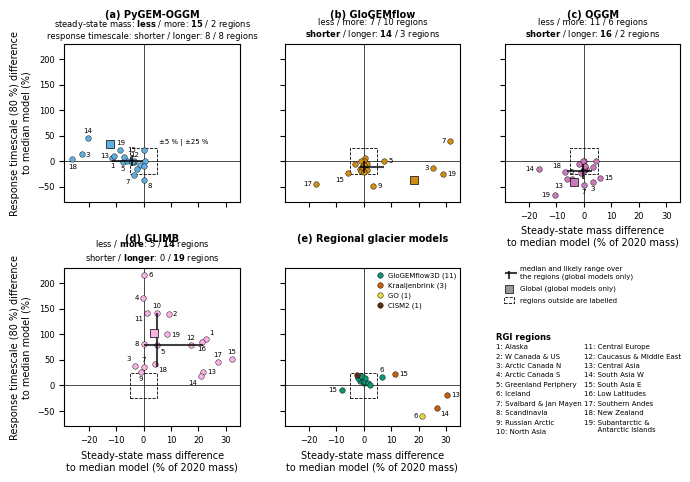

In [14]:
# %% steady-state mass vs. response timescale differences, one panel per global model + one for the regional models
# (needs from the cells above: pd_sys, pd_glob, global_models, regional_models, dict_model_col, regs, reg_names,
#  fig_size_per_model_cm, fs, y_scale, bold_rule, bold_min_regions, alpha, resp_time_change, temp_bin, fig_dir)
import textwrap
from scipy.stats import binomtest
from matplotlib.legend_handler import HandlerBase
from matplotlib.patches import Rectangle

# --- new options ---
show_other_models = False    # True: grey dots of all other glacier models in every panel (as before)
label_ss = 5                 # label a region if |steady-state mass difference| > label_ss (% of 2020 mass) ...
label_tau = 25               # ... or if |response timescale difference| > label_tau
label_tau_unit = 'pct'       # 'pct': label_tau in % (= unit of the y-axis), 'yr': in years (needs pd_sys.d_tau_yr)
show_label_box = True        # dashed box: regions outside of it are labelled (only possible for label_tau_unit='pct')
box_values_in = 'first'      # write the box limits (e.g. ±5 % | ±25 %) next to the box: 'first' panel, 'all', None
subtitle_names_only_first = True   # 'steady-state mass:' / 'response timescale:' written only in panel (a)
try:
    label_pos_manual
except NameError:
    label_pos_manual = {}    # {(model, region number as str): 'right'/'left'/'above'/'below'}, e.g. {('OGGM', '19'): 'left'}

panels = [[m] for m in global_models] + [regional_models]
fig, axs = plt.subplots(2, 3, figsize=(fig_size_per_model_cm[0] / 2.54, fig_size_per_model_cm[1] / 2.54),
                        sharex=True, sharey=True)
y_col = 'd_tau_pct' if y_scale == 'linear' else 'd_tau'
# box limits in the units of the y-axis (log: d_tau = log(tau / tau_median))
y_box = label_tau if y_scale == 'linear' else np.log(1 + label_tau / 100)
y_box_lo = -label_tau if y_scale == 'linear' else np.log(1 - label_tau / 100)
if label_tau_unit == 'yr':
    show_label_box = False   # a box in years can not be drawn on a % axis


def _to_label(row):
    """is the region outside the label box?"""
    if abs(row.d_ss) > label_ss:
        return True
    if label_tau_unit == 'yr':
        return abs(row.d_tau_yr) > label_tau
    return row[y_col] > y_box or row[y_col] < y_box_lo


cross_style = dict(color='k', lw=1.5, alpha=0.75, solid_capstyle='butt', zorder=4)


class HandlerCross(HandlerBase):
    """legend symbol: an asymmetric cross (median not in the centre of the range), like the crosses in the panels"""
    def create_artists(self, legend, orig_handle, x0, y0, width, height, fontsize, trans):
        xc, yc, d = x0 + width / 2, y0 + height / 2, 0.75 * height
        return [plt.Line2D([xc - 1.0 * d, xc + 2.2 * d], [yc, yc], transform=trans, **cross_style),
                plt.Line2D([xc, xc], [yc - 1.6 * d, yc + 0.7 * d], transform=trans, **cross_style)]


class HandlerBox(HandlerBase):
    """legend symbol: small dashed box"""
    def create_artists(self, legend, orig_handle, x0, y0, width, height, fontsize, trans):
        return [Rectangle((x0 + 0.15 * width, y0 - 0.1 * height), 0.7 * width, 1.2 * height, transform=trans,
                          fill=False, ls='--', lw=0.6, ec='k')]


def _is_clear(x):
    """is the direction of the differences over the regions a clear tendency? returns -1, +1 or 0"""
    n_neg, n_pos = (x < 0).sum(), (x > 0).sum()
    if bold_rule == 'n_regions':
        clear = max(n_neg, n_pos) >= bold_min_regions
    else:
        clear = binomtest(int(max(n_neg, n_pos)), int(n_neg + n_pos), 0.5).pvalue < alpha
    return 0 if not clear else (1 if n_pos > n_neg else -1)


def _bf(t, bold):
    # bold text with mathtext (spaces need to be escaped)
    return r'$\bf{' + t.replace(' ', r'\ ') + '}$' if bold else t


def subtitle(_p, first):
    c_ss, c_tau = _is_clear(_p.d_ss), _is_clear(_p.d_tau)
    n = {k: (v < 0).sum() for k, v in [('ss', _p.d_ss), ('tau', _p.d_tau)]}
    p = {k: (v > 0).sum() for k, v in [('ss', _p.d_ss), ('tau', _p.d_tau)]}
    name_ss = 'steady-state mass: ' if (first or not subtitle_names_only_first) else ''
    name_tau = 'response timescale: ' if (first or not subtitle_names_only_first) else ''
    l1 = (f"{name_ss}{_bf('less', c_ss == -1)} / {_bf('more', c_ss == 1)}: "
          f"{_bf(str(n['ss']), c_ss == -1)} / {_bf(str(p['ss']), c_ss == 1)} regions")
    l2 = (f"{name_tau}{_bf('shorter', c_tau == -1)} / {_bf('longer', c_tau == 1)}: "
          f"{_bf(str(n['tau']), c_tau == -1)} / {_bf(str(p['tau']), c_tau == 1)} regions")
    return l1 + '\n' + l2


to_label = []   # (axis, x, y, text, model): placed after tight_layout, see place_labels
ax_points = {}  # coloured points per panel (for the label placement)


def place_labels(to_label, fs):
    """write the region numbers next to the points; for every label, the position (right, left, above, below, ...)
    is chosen that is furthest away from the coloured points of the panel and the labels already placed
    (staying inside the panel; positions to the right are slightly preferred)"""
    cands = [((3, 0), 'left', 'center'), ((-3, 0), 'right', 'center'), ((0, 3), 'center', 'bottom'),
             ((0, -3), 'center', 'top'), ((2.5, 2.5), 'left', 'bottom'), ((2.5, -2.5), 'left', 'top'),
             ((-2.5, 2.5), 'right', 'bottom'), ((-2.5, -2.5), 'right', 'top')]
    pt2px = fig.dpi / 72
    w_char, h_char = 0.6 * (fs - 2) * pt2px, 0.7 * (fs - 2) * pt2px    # approximate size of one digit in pixels
    manual = {'right': cands[0], 'left': cands[1], 'above': cands[2], 'below': cands[3]}
    for ax in dict.fromkeys(a[0] for a in to_label):
        # manually placed labels first, so that the automatic ones avoid them
        _lab = sorted([a for a in to_label if a[0] is ax], key=lambda a: (a[4], a[3]) not in label_pos_manual)
        pts = ax.transData.transform(np.array([(a[1], a[2]) for a in ax_points[ax]]))
        bbox = ax.get_window_extent()
        placed = []
        for _, x, y, t, m in _lab:
            p0 = ax.transData.transform((x, y))
            others = np.vstack([pts[np.hypot(*(pts - p0).T) > 0.5]] + placed) if len(pts) > 1 or placed else np.empty((0, 2))
            best, best_score = None, -np.inf
            for k, ((dx, dy), ha, va) in enumerate(cands):
                cx = p0[0] + dx * pt2px + {'left': 0.5, 'right': -0.5, 'center': 0}[ha] * w_char * len(t)
                cy = p0[1] + dy * pt2px + {'bottom': 0.5, 'top': -0.5, 'center': 0}[va] * h_char
                d = np.min(np.hypot(others[:, 0] - cx, others[:, 1] - cy)) if len(others) else 1e3
                inside = (bbox.x0 + w_char < cx < bbox.x1 - w_char) and (bbox.y0 + h_char < cy < bbox.y1 - h_char)
                score = min(d, 4 * h_char) - (1e3 if not inside else 0) - 0.1 * k
                if score > best_score:
                    best, best_score, best_c = ((dx, dy), ha, va), score, (cx, cy)
            if (m, t) in label_pos_manual:
                best = manual[label_pos_manual[(m, t)]]
                (dx, dy), ha, va = best
                best_c = (p0[0] + dx * pt2px + {'left': 0.5, 'right': -0.5, 'center': 0}[ha] * w_char * len(t),
                          p0[1] + dy * pt2px + {'bottom': 0.5, 'top': -0.5, 'center': 0}[va] * h_char)
            (dx, dy), ha, va = best
            ax.annotate(t, (x, y), xytext=(dx, dy), textcoords='offset points', fontsize=fs - 2, ha=ha, va=va, zorder=5)
            placed.append(np.array([best_c]))


for i_ax, (ax, models) in enumerate(zip(axs.flat, panels)):
    if show_other_models:
        ax.scatter(pd_sys.d_ss, pd_sys[y_col], s=6, color='0.85', zorder=1)
    if show_label_box:
        ax.add_patch(Rectangle((-label_ss, y_box_lo), 2 * label_ss, y_box - y_box_lo, fill=False, ls='--',
                               lw=0.6, ec='k', zorder=2))
        if box_values_in == 'all' or (box_values_in == 'first' and i_ax == 0):
            # limits written at the upper right corner of the box
            ax.annotate(f'±{label_ss} % | ±{label_tau} %', (label_ss, y_box), xytext=(1.5, 1.5),
                        textcoords='offset points', fontsize=fs - 2, ha='left', va='bottom', zorder=5)
    for m in models:
        _p = pd_sys.loc[pd_sys.model == m]
        ax_points.setdefault(ax, []).extend((None, xx, yy) for xx, yy in zip(_p.d_ss, _p[y_col]))
        ax.scatter(_p.d_ss, _p[y_col], s=16, color=dict_model_col[m], edgecolor='k', lw=0.3, zorder=3)
        if len(models) == 1:   # cross: median and 17th to 83rd percentile over the regions
            q = _p[['d_ss', y_col]].quantile([0.17, 0.5, 0.83])
            ax.plot(q.d_ss[[0.17, 0.83]], [q[y_col][0.5]] * 2, **cross_style)
            ax.plot([q.d_ss[0.5]] * 2, q[y_col][[0.17, 0.83]], **cross_style)
            ax.scatter(pd_glob.loc[m, 'd_ss'], pd_glob.loc[m, y_col], marker='s', s=28, color=dict_model_col[m],
                       edgecolor='k', lw=0.5, zorder=6)
            ax_points[ax].append((None, pd_glob.loc[m, 'd_ss'], pd_glob.loc[m, y_col]))   # labels avoid the square
        for _, row in _p.iterrows():
            if _to_label(row):
                to_label.append((ax, row.d_ss, row[y_col], str(int(row.rgi_reg)), m))
    ax.axhline(0, color='k', lw=0.5)
    ax.axvline(0, color='k', lw=0.5)
    ax.tick_params(labelsize=fs - 1)
    if len(models) == 1:
        _p = pd_sys.loc[pd_sys.model == models[0]]
        ax.set_title(f"({chr(97 + i_ax)}) {models[0]}\n\n", fontsize=fs, fontweight='bold', pad=2)
        ax.text(0.5, 1.02, subtitle(_p, first=(i_ax == 0)), transform=ax.transAxes, ha='center', va='bottom',
                fontsize=fs - 1, linespacing=1.1)
    else:
        ax.set_title(f'({chr(97 + i_ax)}) Regional glacier models\n\n', fontsize=fs, fontweight='bold', pad=2)
        ax.legend(handles=[ax.scatter([], [], s=16, color=dict_model_col[m], edgecolor='k', lw=0.3,
                                      label=f"{m} ({len(pd_sys.loc[pd_sys.model == m])})") for m in models],
                  fontsize=fs - 2, loc='upper right', frameon=False, handletextpad=0.1, borderaxespad=0.2)
for ax in axs[:, 0]:
    ax.set_ylabel(f'Response timescale ({abs(resp_time_change)} %) difference\nto median model (%)', fontsize=fs)
for ax in axs[1, :2]:
    ax.set_xlabel('Steady-state mass difference\nto median model (% of 2020 mass)', fontsize=fs)
axs[0, 2].tick_params(labelbottom=True)
axs[0, 2].set_xlabel('Steady-state mass difference\nto median model (% of 2020 mass)', fontsize=fs)

# legend panel: symbols and region numbers
ax_l = axs[1, 2]
ax_l.axis('off')
h, lab, hmap = [], [], {}
if show_other_models:
    h.append(ax_l.scatter([], [], s=6, color='0.85'))
    lab.append('other glacier models')
h.append(ax_l.plot([], [])[0])
lab.append('median and likely range over\nthe regions (global models only)')
hmap[h[-1]] = HandlerCross()   # by instance, not by type (other Line2D handles)
h.append(ax_l.scatter([], [], marker='s', s=28, color='0.6', edgecolor='k', lw=0.5))
lab.append('Global (global models only)')
if show_label_box:
    h.append(Rectangle((0, 0), 1, 1))
    lab.append('regions outside are labelled')
    hmap[h[-1]] = HandlerBox()
elif label_tau_unit == 'yr':
    h.append(ax_l.plot([], [], ls='none')[0])   # TODO: a nicer way to explain this, or only in the caption
    lab.append(f'labelled: |Δ mass| > {label_ss} % or |Δτ| > {label_tau} yr')
ax_l.legend(h, lab, handler_map=hmap, fontsize=fs - 2, loc='upper left',
            bbox_to_anchor=(-0.05, 1.05), frameon=False, handletextpad=0.5, labelspacing=0.8)
reg_txt = [f'{int(r)}: {reg_names[r]}' for r in regs]
reg_txt[-1] = '19: Subantarctic &\n      Antarctic Islands'
y0 = 0.58 if not show_label_box else 0.52   # one legend entry more -> region list a bit lower
for k, t in enumerate(reg_txt):
    col, row = divmod(k, 10)
    ax_l.text(-0.05 + 0.5 * col, y0 - row * (y0 + 0.08) / 10, t, transform=ax_l.transAxes, fontsize=fs - 2, va='top')
ax_l.text(-0.05, y0 + 0.07, 'RGI regions', transform=ax_l.transAxes, fontsize=fs - 1, fontweight='bold', va='top')

plt.tight_layout()
place_labels(to_label, fs)
add = ('_w_other_models' if show_other_models else '') + f'_label_{label_ss}_{label_tau}{label_tau_unit}'
fn_out = (f'{fig_dir}/main_steady_state_vs_resp_time_{abs(resp_time_change)}_per_model_{y_scale}_'
          f'temp_bin_{temp_bin[0]}_{temp_bin[1]}{add}')
plt.savefig(fn_out + '.png', dpi=300)
plt.savefig(fn_out + '.pdf')

In [ ]:
#\begin{figure*}[t]
#\centering
#\includegraphics[width=12cm]{fig/main_steady_state_vs_resp_time_80_per_model_linear_temp_bin_2.0_4.0.pdf}
#\caption{}
#\label{fig:ss_vs_tau_per_model}
#\end{figure*}

Systematic differences of each glacier model to the median model in steady-state glacier mass and in response timescale, for climate scenarios with a global warming of 2.0 to 4.0\,$^{\circ}$C (31 climate scenarios). For every RGI region and climate scenario, the difference of each glacier model to the median model of that region is computed for the steady-state mass (in \% of the 2020 glacier mass, x-axis) and for the response timescale needed to reach 80\,\% of the total mass change (relative to the median model, y-axis; see Sect.~\ref{sec:twoaxes}). Each dot shows the median of these differences over the 31 climate scenarios for one glacier model and one region; the spread over the climate scenarios is shown in Figs.~\ref{TODO} and \ref{TODO}. Panels (a)--(d) show the four global glacier models, panel (e) the regional glacier models (number of regions in brackets). Grey dots show all other glacier models. Black crosses indicate the median and the likely range (17th to 83rd percentile) over the regions, and squares the difference for the global sum of all regions (both only for the global glacier models). Numbers indicate the RGI region for points with a steady-state mass difference larger than 10\,\% or a response timescale difference larger than 50\,\%. The subtitles give the number of regions in which a glacier model has less or more steady-state mass, and a shorter or longer response timescale, than the median model; regions in which the glacier model is itself the median model are not counted. Directions shared by at least 14 of the 19 regions are shown in bold.

Summary (2.0–4.0 °C bin, τ80, non-shifted volume response timescale, OGGM-VAS excluded; numbers from the notebook outputs, sections 2 and 5)

**Method**. For each region and climate scenario, every glacier model is expressed as its difference to the median model, for both steady-state mass and response timescale. This removes the common dependence on the warming level. Per region and glacier model, the median over the 31 scenarios gives its systematic behaviour.
No region is significant. No region shows a significant rank correlation between steady-state and response-timescale differences (exact permutation test, p ≥ 0.05). This is partly a power problem: with 4 glacier models the smallest possible p is 0.083, so 8 of 19 regions cannot be tested at all.

**Pooled test.** Over all regions, the mean rank correlation is 0.16 (p = 0.19). This weak positive tendency comes entirely from GLIMB; without GLIMB, it is −0.11 (p = 0.45). The pooled test treats regions as independent although the same glacier models appear everywhere, so it overstates the available information.

**Conclusion**. There is no indication of a systematic relation between the two kinds of model differences, but the data have little power. Write “no detectable relation”, not “independent”.

**Consistent per-model behaviour (sign test over regions):**
GLIMB has a longer τ80 than the median model in 19/19 regions (median +79 %).
OGGM is shorter in 16/18 regions (p = 0.001, median −19 %).
GloGEMflow is shorter in 14/17 regions (p = 0.013, median −11 %).
GloGEMflow3D is longer in 9/10 regions (p = 0.021, median +8 %).

For steady state, only PyGEM-OGGM is consistent: less mass in 15/17 regions (p = 0.002, median −4 % of 2020 mass).


**Multiple testing**. With 10 tests, a Bonferroni threshold of 0.005 leaves only GLIMB (τ), OGGM (τ) and PyGEM-OGGM (steady state).
**Interpretation**. Each model’s consistent deviation shows up in one quantity, not in both. That fits the absence of a relation.
**Not testable**. CISM2, GO and Kraaijenbrink are available in only 1–3 regions.

GLIMB’s steady state is weaker than it looks. It has more steady-state mass in 14/19 regions (median +5 %), but that is p = 0.064, a tendency only. Its response-timescale signal is much clearer. One possibly interesting point: GloGEMflow (shorter τ) and GloGEMflow3D (longer τ) deviate in opposite directions. That may relate to the ice-flow representation, but this is a guess and needs checking against the model descriptions (TODO).

## 7. Check: other temperature bins and the 50 % response timescale (not shown in the manuscript)

In [13]:
for _change in [-80, -50]:
    _rt = pd_rt.assign(tau=pd_rt[f'resp_time_{_change}%'])
    _both = pd_ss[['rgi_reg', 'model', 'exp', 'temp_ch_ipcc', 'ss']].merge(
        _rt[['rgi_reg', 'model', 'exp', 'tau']], on=['rgi_reg', 'model', 'exp'])
    _both = _both.loc[_both.rgi_reg.isin(regs)]
    _both = _both.loc[_both.groupby(grp).model.transform('count') >= min_models].copy()
    _both['d_ss'] = _both.ss - _both.groupby(grp).ss.transform('median')
    _both['d_tau'] = np.log(_both.tau / _both.groupby(grp).tau.transform('median'))
    for _bin in [[-0.15, 2.0], [2.0, 4.0], [4.0, 7.0]]:
        _b = _both.loc[(_both.temp_ch_ipcc >= _bin[0]) & (_both.temp_ch_ipcc <= _bin[1])]
        _s = _b.groupby(['rgi_reg', 'model'])[['d_ss', 'd_tau']].median().reset_index()
        _m, _p, _ = perm_test_mean_rho(_s, n_perm=2000)
        _mo, _po, _ = perm_test_mean_rho(_s.loc[_s.model != model_out], n_perm=2000)
        print(f'{abs(_change)} %, {_bin[0]} to {_bin[1]}°C: mean rho = {_m:.2f} (p = {_p:.2f}); '
              f'without {model_out}: {_mo:.2f} (p = {_po:.2f})')

/tmp/ipykernel_1748988/2316632513.py:4: RuntimeWarning: Mean of empty slice.
  a, b = a - a.mean(), b - b.mean()
/home/users/lschuster/mambaforge/envs/oggm_gmip3_working/lib/python3.10/site-packages/numpy/core/_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


80 %, -0.15 to 2.0°C: mean rho = 0.06 (p = 0.61); without GLIMB: -0.12 (p = 0.42)
80 %, 2.0 to 4.0°C: mean rho = 0.16 (p = 0.19); without GLIMB: -0.11 (p = 0.46)
80 %, 4.0 to 7.0°C: mean rho = 0.19 (p = 0.11); without GLIMB: -0.08 (p = 0.59)


/tmp/ipykernel_1748988/2316632513.py:4: RuntimeWarning: Mean of empty slice.
  a, b = a - a.mean(), b - b.mean()
/home/users/lschuster/mambaforge/envs/oggm_gmip3_working/lib/python3.10/site-packages/numpy/core/_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


50 %, -0.15 to 2.0°C: mean rho = -0.09 (p = 0.44); without GLIMB: -0.24 (p = 0.10)
50 %, 2.0 to 4.0°C: mean rho = 0.11 (p = 0.36); without GLIMB: -0.20 (p = 0.20)
50 %, 4.0 to 7.0°C: mean rho = 0.22 (p = 0.08); without GLIMB: 0.01 (p = 0.95)


50 %, -0.15 to 2.0°C: mean rho = -0.09 (p = 0.44); without GLIMB: -0.24 (p = 0.10)


50 %, 2.0 to 4.0°C: mean rho = 0.11 (p = 0.36); without GLIMB: -0.20 (p = 0.20)


50 %, 4.0 to 7.0°C: mean rho = 0.22 (p = 0.08); without GLIMB: 0.01 (p = 0.95)


**Attention:** in the 4.0 to 7.0°C bin, almost all glacier mass is lost in many regions, so the steady-state differences between the glacier models are small (all close to -100 %) and their ranks are mostly random. The 2.0 to 4.0°C bin is therefore used for the figure.

# 8. after 80 ys vs steady-state scatterplot in similar style ..

steady-state difference vs. pd_sys.d_ss: 92 points compared, max abs. difference 15.848 %-points (should be ~0, otherwise other reference!)
     model  reg_num  d_80  d_ss
     GLIMB        9   1.6  -1.1
        GO        6  -5.3  22.2
GloGEMflow        9 -17.4   3.5
      OGGM        3  -1.3   6.3


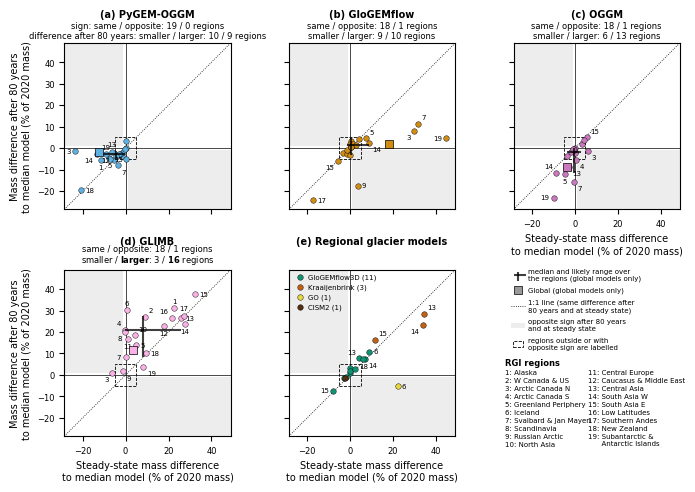

In [15]:
# %% Supplement: mass difference after 80 years vs. at steady state, one panel per global model + regional models
# Same 2x3 layout as the steady-state vs. response timescale scatterplot above. Points in the shaded quadrants:
# the model is above the median after 80 years but below it at steady state (or the other way round).
# Uses from the cells above: global_models, regional_models, dict_model_col, regs, reg_names, fig_size_per_model_cm,
# fs, temp_bin, fig_dir, bold_rule, alpha, pd_sys (only for a check), and the functions
# HandlerCross, HandlerBox, cross_style, _is_clear, _bf, place_labels (from the previous cell).

# --- settings ---
fn_steady_state_y80 = 'PartB_data/steady_state_relative_volume_change.csv'   # change to your local paths
fn_after80_y80 = 'PartB_data/after80yrs_relative_volume_change.csv'
reference_y80 = 'global4'    # 'global4': median of the four global models (as in the worldmap), 'all_models': all models
flip_tol = 1                 # opposite signs only counted (and shaded) if both |differences| > flip_tol (% of 2020 mass)
label_lim_y80 = 5            # label a region if one of its differences is > label_lim_y80 (% of 2020 mass) ...
label_opposite = True        # ... or if the signs are opposite
label_pos_manual_y80 = {}    # as label_pos_manual above, e.g. {('OGGM', '19'): 'left'}

# --- data: difference of every model to the reference, median over the climate scenarios of the temperature bin ---
rc = 'relative volume change (in %)'
key = ['rgi_reg', 'model_author', 'gcm', 'period_scenario']
_ss = pd.read_csv(fn_steady_state_y80, index_col=0, dtype={'rgi_reg': str})
_80 = pd.read_csv(fn_after80_y80, index_col=0, dtype={'rgi_reg': str})
pd_y = _80[key + ['temp_ch_ipcc', rc]].merge(_ss[key + [rc]], on=key, suffixes=('_80', '_ss'), validate='one_to_one')
assert len(pd_y) == len(_80) == len(_ss)
pd_y['model'] = pd_y.model_author.replace({'PyGEM-OGGM_v13': 'PyGEM-OGGM', 'OGGM_v16': 'OGGM'})
pd_y = pd_y.loc[(pd_y.temp_ch_ipcc >= temp_bin[0]) & (pd_y.temp_ch_ipcc <= temp_bin[1])].copy()
if temp_bin == [2.0, 4.0]:
    np.testing.assert_allclose(len(pd_y.groupby(['gcm', 'period_scenario'])), 31)

ref_models = global_models if reference_y80 == 'global4' else list(pd_y.model.unique())
for p in ['80', 'ss']:
    _ref = pd_y.loc[pd_y.model.isin(ref_models)].groupby(['rgi_reg', 'gcm', 'period_scenario'])[f'{rc}_{p}'].median()
    pd_y = pd_y.join(_ref.rename(f'ref_{p}'), on=['rgi_reg', 'gcm', 'period_scenario'])
    pd_y[f'd_{p}'] = pd_y[f'{rc}_{p}'] - pd_y[f'ref_{p}']
pd_y_med = pd_y.groupby(['rgi_reg', 'model'])[['d_80', 'd_ss']].median().reset_index()
pd_y_glob = pd_y_med.loc[pd_y_med.rgi_reg == 'Global'].set_index('model')
pd_y_reg = pd_y_med.loc[pd_y_med.rgi_reg != 'Global'].copy()
pd_y_reg['reg_num'] = pd_y_reg.rgi_reg.astype(int)

# check: are the steady-state differences the same as in the scatterplot above (same reference)?
_chk = pd_y_reg.merge(pd_sys.assign(reg_num=pd_sys.rgi_reg.astype(int))[['reg_num', 'model', 'd_ss']],
                      on=['reg_num', 'model'], suffixes=('', '_sys'))
print(f'steady-state difference vs. pd_sys.d_ss: {len(_chk)} points compared, max abs. difference '
      f'{np.abs(_chk.d_ss - _chk.d_ss_sys).max():.3f} %-points (should be ~0, otherwise other reference!)')

# x: steady state (as in the scatterplot above), y: after 80 years
pd_y_reg['opp'] = ((np.sign(pd_y_reg.d_80) != np.sign(pd_y_reg.d_ss)) &
                   (pd_y_reg.d_80.abs() > flip_tol) & (pd_y_reg.d_ss.abs() > flip_tol))
pd_y_reg['d_abs'] = pd_y_reg.d_80.abs() - pd_y_reg.d_ss.abs()   # < 0: smaller difference after 80 years


def subtitle_y80(_p, first):
    n_opp = int(_p.opp.sum())
    c_abs = _is_clear(_p.d_abs)
    name_sign = 'sign: ' if first else ''
    name_abs = 'difference after 80 years: ' if first else ''
    l1 = f"{name_sign}same / opposite: {len(_p) - n_opp} / {n_opp} regions"
    l2 = (f"{name_abs}{_bf('smaller', c_abs == -1)} / {_bf('larger', c_abs == 1)}: "
          f"{_bf(str((_p.d_abs < 0).sum()), c_abs == -1)} / {_bf(str((_p.d_abs > 0).sum()), c_abs == 1)} regions")
    return l1 + '\n' + l2


# same axis limits for x and y (-> 1:1 line at 45°)
_v = np.concatenate([pd_y_reg[['d_ss', 'd_80']].values.ravel(), pd_y_glob[['d_ss', 'd_80']].values.ravel()])
lo, hi = _v.min(), _v.max()
lo, hi = lo - 0.06 * (hi - lo), hi + 0.06 * (hi - lo)

fig, axs = plt.subplots(2, 3, figsize=(fig_size_per_model_cm[0] / 2.54, fig_size_per_model_cm[1] / 2.54),
                        sharex=True, sharey=True)
to_label, ax_points = [], {}   # used by place_labels (from the previous cell)
_label_pos_manual_tau = label_pos_manual
label_pos_manual = label_pos_manual_y80
col_opp = '0.93'

for i_ax, (ax, models) in enumerate(zip(axs.flat, panels)):
    # shaded quadrants: opposite signs
    ax.add_patch(Rectangle((lo, flip_tol), -flip_tol - lo, hi - flip_tol, fc=col_opp, ec='none', zorder=0))
    ax.add_patch(Rectangle((flip_tol, lo), hi - flip_tol, -flip_tol - lo, fc=col_opp, ec='none', zorder=0))
    ax.plot([lo, hi], [lo, hi], color='k', lw=0.6, ls=':', zorder=1)   # 1:1 line
    ax.add_patch(Rectangle((-label_lim_y80, -label_lim_y80), 2 * label_lim_y80, 2 * label_lim_y80, fill=False,
                           ls='--', lw=0.6, ec='k', zorder=2))
    for m in models:
        _p = pd_y_reg.loc[pd_y_reg.model == m]
        ax_points.setdefault(ax, []).extend((None, xx, yy) for xx, yy in zip(_p.d_ss, _p.d_80))
        ax.scatter(_p.d_ss, _p.d_80, s=16, color=dict_model_col[m], edgecolor='k', lw=0.3, zorder=3)
        if len(models) == 1:   # cross: median and 17th to 83rd percentile over the regions
            q = _p[['d_ss', 'd_80']].quantile([0.17, 0.5, 0.83])
            ax.plot(q.d_ss[[0.17, 0.83]], [q.d_80[0.5]] * 2, **cross_style)
            ax.plot([q.d_ss[0.5]] * 2, q.d_80[[0.17, 0.83]], **cross_style)
            ax.scatter(pd_y_glob.loc[m, 'd_ss'], pd_y_glob.loc[m, 'd_80'], marker='s', s=28, color=dict_model_col[m],
                       edgecolor='k', lw=0.5, zorder=6)
            ax_points[ax].append((None, pd_y_glob.loc[m, 'd_ss'], pd_y_glob.loc[m, 'd_80']))
        for _, row in _p.iterrows():
            if (max(abs(row.d_ss), abs(row.d_80)) > label_lim_y80) or (label_opposite and row.opp):
                to_label.append((ax, row.d_ss, row.d_80, str(row.reg_num), m))
    ax.axhline(0, color='k', lw=0.5)
    ax.axvline(0, color='k', lw=0.5)
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_aspect('equal', adjustable='box')
    ax.tick_params(labelsize=fs - 1)
    if len(models) == 1:
        ax.set_title(f"({chr(97 + i_ax)}) {models[0]}\n\n", fontsize=fs, fontweight='bold', pad=2)
        ax.text(0.5, 1.02, subtitle_y80(pd_y_reg.loc[pd_y_reg.model == models[0]], first=(i_ax == 0)),
                transform=ax.transAxes, ha='center', va='bottom', fontsize=fs - 1, linespacing=1.1)
    else:
        ax.set_title(f'({chr(97 + i_ax)}) Regional glacier models\n\n', fontsize=fs, fontweight='bold', pad=2)
        ax.legend(handles=[ax.scatter([], [], s=16, color=dict_model_col[m], edgecolor='k', lw=0.3,
                                      label=f"{m} ({len(pd_y_reg.loc[pd_y_reg.model == m])})") for m in models],
                  fontsize=fs - 2, loc='upper left', frameon=False, handletextpad=0.1, borderaxespad=0.2)
xlab = 'Steady-state mass difference\nto median model (% of 2020 mass)'
for ax in axs[:, 0]:
    ax.set_ylabel('Mass difference after 80 years\nto median model (% of 2020 mass)', fontsize=fs)
for ax in axs[1, :2]:
    ax.set_xlabel(xlab, fontsize=fs)
axs[0, 2].tick_params(labelbottom=True)
axs[0, 2].set_xlabel(xlab, fontsize=fs)

# legend panel
ax_l = axs[1, 2]
ax_l.axis('off')
h = [ax_l.plot([], [])[0], ax_l.scatter([], [], marker='s', s=28, color='0.6', edgecolor='k', lw=0.5),
     plt.Line2D([], [], color='k', lw=0.6, ls=':'), Rectangle((0, 0), 1, 1, fc=col_opp, ec='none'),
     Rectangle((0, 0), 1, 1)]
lab = ['median and likely range over\nthe regions (global models only)', 'Global (global models only)',
       '1:1 line (same difference after\n80 years and at steady state)',
       'opposite sign after 80 years\nand at steady state', 'regions outside or with\nopposite sign are labelled']
hmap = {h[0]: HandlerCross(), h[4]: HandlerBox()}   # by instance (h[0] and h[2] are both Line2D)
ax_l.legend(h, lab, handler_map=hmap, fontsize=fs - 2, loc='upper left', bbox_to_anchor=(-0.05, 1.05),
            frameon=False, handletextpad=0.5, labelspacing=0.8)
reg_txt = [f'{int(r)}: {reg_names[r]}' for r in regs]
reg_txt[-1] = '19: Subantarctic &\n      Antarctic Islands'
y0 = 0.40
for k, t in enumerate(reg_txt):
    col, row = divmod(k, 10)
    ax_l.text(-0.05 + 0.5 * col, y0 - row * (y0 + 0.08) / 10, t, transform=ax_l.transAxes, fontsize=fs - 2, va='top')
ax_l.text(-0.05, y0 + 0.07, 'RGI regions', transform=ax_l.transAxes, fontsize=fs - 1, fontweight='bold', va='top')

plt.tight_layout()
place_labels(to_label, fs)
label_pos_manual = _label_pos_manual_tau   # back to the settings of the previous figure
fn_out = (f'{fig_dir}/suppl_after80yrs_vs_steady_state_per_model_temp_bin_{temp_bin[0]}_{temp_bin[1]}_'
          f'ref_{reference_y80}_label_{label_lim_y80}')
plt.savefig(fn_out + '.png', dpi=300)
plt.savefig(fn_out + '.pdf')

# numbers for the text
print(pd_y_reg.loc[pd_y_reg.opp].sort_values(['model', 'reg_num'])[['model', 'reg_num', 'd_80', 'd_ss']].round(1)
      .to_string(index=False))